# A simple IPERLITE wildfire signal workflow

This example loads development-catalog IPERLITE L1C data over a small Namibia AOI, calculates four spectral indices, and compares a July median composite with an August scene using openEO processes. The dates are available acquisitions, not verified fire dates; treat the result as a demonstration of the workflow, not a confirmed burn map.

L1C contains top-of-atmosphere reflectance. This deliberately simple example does not apply atmospheric correction or cloud masking.

In [7]:
import openeo

connection = openeo.connect("openeo.terrascope.be").authenticate_oidc()

Authenticated using refresh token.


# A simple IPERLITE wildfire signal workflow

This example loads development-catalog IPERLITE L1C data over a small Namibia AOI, calculates five spectral indices, and compares a July median composite with an August scene using openEO processes. The dates are available acquisitions, not verified fire dates; treat the result as a demonstration of the workflow, not a confirmed burn map.

L1C contains top-of-atmosphere reflectance. This deliberately simple example does not apply atmospheric correction or cloud masking.

In [8]:
IPERLITE_L1C = "https://stac-api-dev.vgt.vito.be/collections/terrascope-iperlite-l1c-cog-v1"

# Small AOI in Namibia, covered by the July and August scenes.
aoi = {
    "type": "Polygon",
    "coordinates": [[
        [15.1741065, -23.6265988],
        [15.1741065, -23.5781422],
        [15.0532065, -23.5781422],
        [15.0532065, -23.6265988],
        [15.1741065, -23.6265988],
    ]],
}

pre_period = ["2026-07-06", "2026-07-13"]
post_period = ["2026-08-03", "2026-08-04"]

# RTOA bands nearest to 531, 550, 570, 665, 680, 705, 750, 783, and 842 nm.
bands = ["RTOA18", "RTOA23", "RTOA33", "RTOA52", "RTOA58", "RTOA66", "RTOA84", "RTOA101", "RTOA122"]
print(f"Pre-fire window: {pre_period}; post-fire window: {post_period}")

Pre-fire window: ['2026-07-06', '2026-07-13']; post-fire window: ['2026-08-03', '2026-08-04']


## 2. Load the selected L1C data

`load_stac` sends the spatial, temporal, and band selection to openEO. The subset is loaded for the AOI and date range instead of downloading complete scenes.

In [9]:
cube = connection.load_stac(
    url=IPERLITE_L1C,
    spatial_extent=aoi,
    temporal_extent=["2026-07-06", "2026-08-04"],
    bands=bands,
)
cube

In [10]:
# cube.execute_batch(title="cube loading")

## 3. Calculate five spectral indices

These indices compare complementary vegetation signals using IPERLITE's VNIR bands: broad greenness, chlorophyll-sensitive red-edge response, short-term photosynthetic stress, chlorophyll absorption depth, and a red/NIR burned-area signal.

- **NDVI** = (R842 - R665) / (R842 + R665): a familiar broad-band greenness baseline for vegetation change ([Tucker, 1979](https://doi.org/10.1016/0034-4257(79)90013-0)).
- **CIre** = R783 / R705 - 1: a red-edge chlorophyll proxy that complements NDVI, which can be less sensitive to chlorophyll differences in dense vegetation ([Gitelson et al., 2003](https://doi.org/10.1078/0176-1617-00887)). The wavelengths here are the nearest IPERLITE bands to the target wavelengths.
- **PRI** = (R531 - R570) / (R531 + R570): a signal associated with photosynthetic light-use efficiency and xanthophyll-cycle activity; it may respond to physiological stress, but is also sensitive to illumination and canopy conditions ([Gamon et al., 1992](https://doi.org/10.1016/0034-4257(92)90059-S)).
- **CAD680** = 1 - R680 / Rcontinuum: estimates the depth of the chlorophyll absorption feature near 680 nm relative to a local spectral baseline. Here, Rcontinuum is linearly interpolated between 550 and 750 nm. This is a simplified continuum-depth calculation used in this example. [Yang et al. (2006)](https://doi.org/10.1631/jzus.2006.A2002) discuss a related chlorophyll absorption continuum index; that paper is included as background, not as the source for this specific 550/750 nm implementation.
- **BAI** = 1 / ((0.1 - R665)^2 + (0.06 - R842)^2): measures inverse spectral distance from a reference red/NIR reflectance point associated with burned surfaces ([Chuvieco et al., 2002](https://doi.org/10.1080/01431160210153129)). It is a VNIR burned-area indicator, not NBR.

BAI's reference values assume reflectance in 0-1 units. `BAI_REFLECTANCE_SCALE` below is set to 1.0 for data already in that range; use 0.0001 instead if `load_stac` returns raw integer values stored with a 0.0001 scale. Check representative RTOA values before interpreting BAI. These are exploratory signals from L1C top-of-atmosphere reflectance, without atmospheric correction or cloud masking.

In [11]:
r531 = cube.band("RTOA18")
r550 = cube.band("RTOA23")
r570 = cube.band("RTOA33")
r665 = cube.band("RTOA52")
r680 = cube.band("RTOA58")
r705 = cube.band("RTOA66")
r750 = cube.band("RTOA84")
r783 = cube.band("RTOA101")
r842 = cube.band("RTOA122")

ndvi = ((r842 - r665) / (r842 + r665)).add_dimension(
    name="bands", label="NDVI", type="bands"
)
cire = (r783 / r705 - 1).add_dimension(
    name="bands", label="CIre", type="bands"
)
pri = ((r531 - r570) / (r531 + r570)).add_dimension(
    name="bands", label="PRI", type="bands"
)

continuum_680 = r550 + (r750 - r550) * (130 / 200)
cad680 = (1 - r680 / continuum_680).add_dimension(
    name="bands", label="CAD680", type="bands"
)

# Use 1.0 for reflectance in 0-1 units, or 0.0001 for raw values scaled by 10000.
BAI_REFLECTANCE_SCALE = 1.0
red_reflectance = r665 * BAI_REFLECTANCE_SCALE
nir_reflectance = r842 * BAI_REFLECTANCE_SCALE
bai_distance_squared = (
    (0.1 - red_reflectance) * (0.1 - red_reflectance)
    + (0.06 - nir_reflectance) * (0.06 - nir_reflectance)
)
bai = (1 / bai_distance_squared).add_dimension(
    name="bands", label="BAI", type="bands"
)

indices = (
    ndvi.merge_cubes(cire)
    .merge_cubes(pri)
    .merge_cubes(cad680)
    .merge_cubes(bai)
)
indices

In [12]:
# indices.execute_batch(title="indices calculation")

## 4. Compare pre- and post-period composites

`filter_temporal` selects each window, and `reduce_dimension` computes a per-pixel median over its acquisitions. Subtracting the pre composite from the post composite gives the change in each index.

In [6]:
pre_indices = indices.filter_temporal(pre_period).reduce_dimension(
    dimension="t", reducer="median"
)
post_indices = indices.filter_temporal(post_period).reduce_dimension(
    dimension="t", reducer="median"
)

change = (post_indices - pre_indices).rename_labels(
    dimension="bands",
    target=["dNDVI", "dCIre", "dPRI", "dCAD680", "dBAI"],
)
change

## 5. Export and inspect the change indices

Submit the resulting five-band cube as an openEO batch job. The NetCDF output can then be opened locally with xarray.

In [13]:
change.execute_batch(
    title="IPERLITE spectral index change",
    outputfile="change_detection_spectral.nc",
)

0:00:00 Job 'j-261014075312414881354ecc189287d4': send 'start'
0:00:25 Job 'j-261014075312414881354ecc189287d4': created (progress 0%)
0:00:30 Job 'j-261014075312414881354ecc189287d4': queued (progress 0%)
0:00:37 Job 'j-261014075312414881354ecc189287d4': queued (progress 0%)
0:00:45 Job 'j-261014075312414881354ecc189287d4': queued (progress 0%)
0:00:55 Job 'j-261014075312414881354ecc189287d4': queued (progress 0%)
0:01:08 Job 'j-261014075312414881354ecc189287d4': queued (progress 0%)
0:01:23 Job 'j-261014075312414881354ecc189287d4': queued (progress 0%)
0:01:43 Job 'j-261014075312414881354ecc189287d4': queued (progress 0%)
0:02:07 Job 'j-261014075312414881354ecc189287d4': queued (progress 0%)
0:02:37 Job 'j-261014075312414881354ecc189287d4': queued (progress 0%)
0:03:14 Job 'j-261014075312414881354ecc189287d4': queued (progress 0%)
0:04:03 Job 'j-261014075312414881354ecc189287d4': queued (progress 0%)
0:05:01 Job 'j-261014075312414881354ecc189287d4': queued (progress 0%)
0:06:02 Job '

<BatchJob job_id='j-261014075312414881354ecc189287d4'>

The `d` prefix means post minus pre. A negative `dCAD680` indicates a reduction in the 680 nm chlorophyll absorption feature. A positive `dBAI` means the red/NIR reflectance pair moved closer to BAI's reference point; it is not proof of burning. BAI is a VNIR indicator and is not a substitute for NBR, which requires SWIR data.

In [16]:
import xarray as xr

change_ds = xr.open_dataset("change_detection_spectral.nc")
change_ds

<xarray.Dataset> Size: 4MB
Dimensions:  (y: 272, x: 678)
Coordinates:
  * y        (y) float64 2kB -23.58 -23.58 -23.58 ... -23.63 -23.63 -23.63
  * x        (x) float64 5kB 15.05 15.05 15.05 15.05 ... 15.17 15.17 15.17 15.17
Data variables:
    crs      |S1 1B ...
    dNDVI    (y, x) float32 738kB ...
    dCIre    (y, x) float32 738kB ...
    dPRI     (y, x) float32 738kB ...
    dCAD680  (y, x) float32 738kB ...
    dBAI     (y, x) float32 738kB ...
Attributes:
    Conventions:  CF-1.9
    institution:  VITO Terrascope openEO API - 0.74.0a2.dev20261011+211
    description:  
    title:

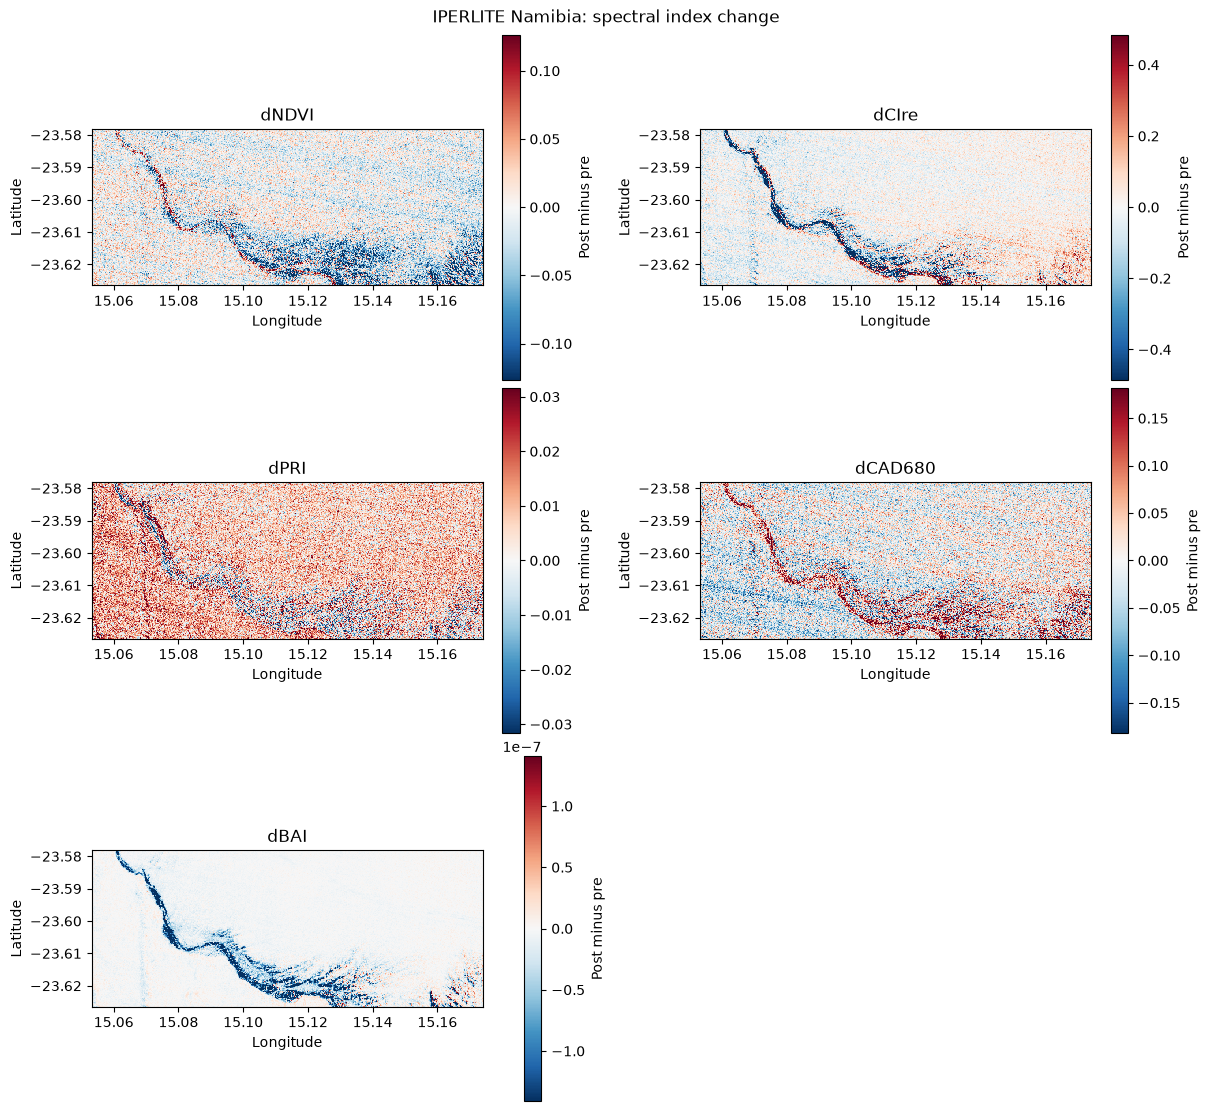

In [17]:
import matplotlib.pyplot as plt
import numpy as np

index_names = ["dNDVI", "dCIre", "dPRI", "dCAD680", "dBAI"]
fig, axes = plt.subplots(3, 2, figsize=(12, 11), constrained_layout=True)
axes.flat[-1].set_visible(False)
extent = [
    float(change_ds.x.min()),
    float(change_ds.x.max()),
    float(change_ds.y.min()),
    float(change_ds.y.max()),
]

for ax, name in zip(axes.flat, index_names):
    values = change_ds[name].values
    limit = float(np.nanpercentile(np.abs(values), 98))
    if not np.isfinite(limit) or limit == 0:
        limit = 1e-6
    image = ax.imshow(
        values,
        extent=extent,
        origin="upper",
        cmap="RdBu_r",
        vmin=-limit,
        vmax=limit,
        interpolation="nearest",
    )
    ax.set_title(name)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    fig.colorbar(image, ax=ax, label="Post minus pre")

fig.suptitle("IPERLITE Namibia: spectral index change")
plt.show()

## Conclusion

The July-to-August comparison shows a narrow, branching feature with negative changes in NDVI and CIre, indicating reduced greenness and a changed red-edge signal in that area. PRI and CAD680 show more mixed changes. BAI adds an exploratory red/NIR burned-area signal, but it is not NBR and should only be interpreted after confirming the RTOA reflectance scale. Together, these layers identify a spatially coherent spectral change worth investigating, but they do not establish that it was caused by fire.

This is a preliminary comparison of L1C top-of-atmosphere data with no cloud mask or atmospheric correction. Clouds, surface moisture, exposed soil, vegetation change, or scene-to-scene differences could also contribute. Each panel uses its own color scale, so color intensity should only be compared within a panel. Confirm a fire interpretation against an independent fire perimeter or incident record and, if available, cloud-free corrected imagery.